# 📊 Laporan Analisis Media Sosial (AMS)
## Analisis Komparasi Opini Publik terhadap Kebijakan Fiskal, Moneter, dan Pasar Modal Indonesia pada Diskusi YouTube

* **Mata Kuliah:** Analisis Media Sosial (AMS)
* **Dataset:** 3.634 Komentar YouTube dari 4 Video Kebijakan Ekonomi Nasional (Kanal Ferry Irwandi)
* **Metode:** *Web Scraping (YouTube InnerTube API)*, *Text Preprocessing*, *Indonesian Slang Normalization*, *Heuristic Non-Substantive Filtering*, *Lexicon-Based Sentiment Analysis*, dan *Cross-Video Engagement Comparison*.

---

### 🎯 Tujuan Analisis
1. **Scraping Data YouTube Skala Menengah (3.500+ Komentar):** Mengumpulkan opini publik lintas video terkait kebijakan ekonomi Indonesia terkini (Menteri Keuangan Purbaya Yudhi Sadewa, pemindahan dana SAL Rp400 Triliun ke Himbara, gejolak pasar saham/MSCI, dan trilema moneter).
2. **Analisis Komparasi Antar Video (*Video-to-Video Analysis*):** Menjawab pertanyaan pokok tugas:
   * **Berapa banyak yang suka (*engagement level* & *like count*)?**
   * **Apa bahasannya (*topic extraction, n-grams, & word cloud*)?**
3. **Penyaringan Komentar Berkualitas (*Substantive vs Non-Substantive*):** Memisahkan komentar diskusi berbobot dari bot promo (slot/judi online/skincare), penanda waktu (*timestamp*), *mention reply*, emotikon murni, dan basa-basi (*phatic comments*).
4. **Analisis Sentimen Publik:** Mengukur persepsi masyarakat (positif, netral, negatif) terhadap arah kebijakan ekonomi pemerintah baru.


---
## 📑 Cuplikan Sampling Dataset (Markdown Colab Table)
Sesuai instruksi tugas untuk menampilkan sampling dataset di Markdown Colab:

| Comment ID | Video Topik | Author | Cuplikan Komentar Asli (`text_raw`) | Likes | Tipe / Kategori | Sentimen |
|:---|:---|:---|:---|:---:|:---:|:---:|
| `C00001` | Kebijakan Purbaya | `@ferryirwandi` | "Hallo warga sipil sekalian selamat menyaksikan dan selamat menonton" | 241 | `substantive` | Positif |
| `C00002` | Kebijakan Purbaya | `@fajrinanggoro6766` | "Selama kamu bekerja dengan orang, kerja sewajarnya saja by Purbaya..." | 632 | `substantive` | Positif |
| `C00005` | Kebijakan Purbaya | `@ikhsan7539` | "next undang pak purbaya di devils advokat pakk" | 6 | `substantive` | Netral |
| `C00010` | Kebijakan Purbaya | `@kukuhgalangr` | "ngaco ini menkeu yg baru, belum apa2 udh blunder diwawancara bloomberg..." | 0 | `substantive` | Negatif |
| `C00012` | Kebijakan Purbaya | `@user-zn8...` | "❤‍🔥❤‍🔥❤‍🔥" | 2 | `emoji_or_symbol_only` | Netral |
| `C00045` | Dana SAL 400T | `@investor_pemula` | "Uang 400T ditaruh di himbara itu bahaya kalau kredit macet membengkak..." | 749 | `substantive` | Negatif |
| `C00120` | Dana SAL 400T | `@promo_berkah` | "SIAP 46 BERKAH 99 KUNJUNGI LINK..." | 0 | `suspected_promo` | Netral |
| `C00640` | Pasar Modal MSCI | `@trader_saham` | "MSCI rebalancing bikin asing capital outflow, IHSG nyungsep parah..." | 617 | `substantive` | Negatif |
| `C00750` | Pasar Modal MSCI | `@edukasi_finansial` | "Penjelasannya sangat bagus dan masuk akal, tercerahkan sekali bang!" | 185 | `substantive` | Positif |
| `C01100` | Trilema Moneter | `@mahasiswa_fe` | "04:15 - trilema moneter pas banget jelasin kondisi BI saat ini" | 12 | `timestamp` | Netral |

*Total Observasi:* **3.634 komentar mentah** $\rightarrow$ **3.581 komentar bersih (3.413 substantif)**.


### 1. Import Library dan Konfigurasi


In [ ]:
import os
import re
import html
import unicodedata
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from matplotlib.patches import Patch

# Konfigurasi visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 80)
print("Semua library berhasil dimuat!")


### 2. Memuat Dataset Mentah Komentar YouTube


In [ ]:
# Path dataset (kompatibel lokal maupun Google Colab)
DATA_PATH = "data/raw_youtube_comments.csv"

# Jika dijalankan langsung di Colab tanpa upload manual, unduh otomatis dari GitHub repo
if not os.path.exists(DATA_PATH):
    GITHUB_RAW_URL = "https://raw.githubusercontent.com/favjiw/ams-youtube-economic-sentiment/main/data/raw_youtube_comments.csv"
    print(f"Mengunduh dataset dari: {GITHUB_RAW_URL}...")
    df_raw = pd.read_csv(GITHUB_RAW_URL)
else:
    df_raw = pd.read_csv(DATA_PATH)

print(f"Dimensi data mentah: {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom")
display(df_raw[['video_title', 'author', 'text_raw', 'like_count']].head(5))


### 3. Distribusi Observasi per Video


In [ ]:
video_summary = df_raw.groupby(['video_category', 'video_title']).agg(
    total_komentar=('comment_id', 'count'),
    total_likes=('like_count', 'sum'),
    rata_rata_likes=('like_count', 'mean'),
    komentar_terbanyak_likes=('like_count', 'max')
).reset_index()

print("=== DISTRIBUSI KOMENTAR & ENGAGEMENT PER VIDEO ===")
display(video_summary)


### 4. Pipeline Text Cleaning & Normalisasi Slang Indonesia
Pada tahap ini teks mentah dibersihkan dari artefak HTML (`<br>`, tag HTML, HTML entities), URL, mention awal, serta dinormalisasi menggunakan kamus slang kata informal Indonesia (misal: *yg $\rightarrow$ yang, gak $\rightarrow$ tidak, udh $\rightarrow$ sudah*).


In [ ]:
BR_TAG_RE = re.compile(r"<br\s*/?>", re.I)
HTML_TAG_RE = re.compile(r"<[^>]+>")
URL_RE = re.compile(r"(https?://\S+|www\.\S+)", re.I)
WHITESPACE_RE = re.compile(r"\s+")
REPEATED_CHAR_RE = re.compile(r"([a-z]){2,}")
EMOJI_RE = re.compile("[🌀-🫿☀-➿]")
TIMESTAMP_RE = re.compile(r"^\s*(\d{1,2}[:.]){1,2}\d{1,2}(\D|$)|^\s*\d+\s*menit", re.I)
MENTION_RE = re.compile(r"^@\S+")
NO_ALNUM_RE = re.compile(r"^[\W_]+$", re.UNICODE)
WORD_RE = re.compile(r"[a-z]+")

PROMO_RE = re.compile(
    r"berkah\s*99|siap\s*46|estetik kreatif banget|paling the best|selalu bikin kagum|slot|gacor|maxwin|depo|withdraw|wa\.me|t\.me",
    re.I,
)

SLANG = {
    r"gak|ga|nggak|ngga|enggak|engga|gk|tdk": "tidak",
    r"tp": "tapi",
    r"dlm": "dalam",
    r"yg": "yang",
    r"dgn|dg": "dengan",
    r"utk": "untuk",
    r"krn|karna": "karena",
    r"udh|sdh|udah": "sudah",
    r"blm": "belum",
    r"jg": "juga",
    r"bgt|bngt": "banget",
    r"kalo|klo": "kalau",
    r"aja": "saja",
    r"emg|emang": "memang",
    r"org": "orang",
    r"dr": "dari",
    r"pd": "pada",
    r"bs": "bisa",
    r"lg": "lagi",
    r"trs": "terus",
    r"gw|gue|gua|sy": "saya",
    r"lu|lo": "kamu",
    r"bapack|bapak2": "bapak",
    r"bener": "benar",
    r"dapet": "dapat",
    r"sampe": "sampai",
    r"kyk|kayak": "seperti",
    r"tau": "tahu",
    r"cmn|cuman": "cuma",
}
SLANG_PATTERNS = [(re.compile(rf"(?:{k})"), v) for k, v in SLANG.items()]

PHATIC_WORDS = {
    "semangat", "yes", "yess", "hi", "hai", "halo", "hello", "gg", "nyimak",
    "up", "first", "pertama", "mantap", "salam", "izin", "absen", "ok", "oke",
    "hadir", "hadirrr", "hadirr", "wow", "wew", "yayayayaya", "soon", "omaga",
    "setuju", "nice", "top", "mantul"
}

def clean_text(text: str) -> str:
    text = BR_TAG_RE.sub(" ", str(text))
    text = HTML_TAG_RE.sub(" ", text)
    text = html.unescape(text)
    text = URL_RE.sub("[URL]", text)
    return WHITESPACE_RE.sub(" ", text).strip()

def normalize(text: str) -> str:
    text = unicodedata.normalize("NFKC", text).lower()
    text = REPEATED_CHAR_RE.sub(r"", text)
    for pattern, replacement in SLANG_PATTERNS:
        text = pattern.sub(replacement, text)
    return WHITESPACE_RE.sub(" ", text).strip()

def styled_ratio(text: str) -> float:
    alnum_count = sum(c.isalnum() for c in text)
    if alnum_count == 0:
        return 0.0
    styled_count = sum(0x1D400 <= ord(c) <= 0x1D7FF for c in text)
    return styled_count / alnum_count

def classify_non_substantive(row: pd.Series) -> str:
    text = row["text_clean"].strip()
    norm = row["text_norm"].strip()
    tokens = WORD_RE.findall(norm)
    n_words = row["n_words"]

    if row["is_promo_pattern"] or row["styled_ratio"] > 0.3:
        return "suspected_promo"
    if TIMESTAMP_RE.match(text) and n_words <= 8:
        return "timestamp"
    if MENTION_RE.match(text) and n_words <= 6:
        return "reply_mention"
    if NO_ALNUM_RE.match(text):
        return "emoji_or_symbol_only"
    if tokens and len(tokens) <= 3 and all(w in PHATIC_WORDS for w in tokens):
        return "phatic"
    if row["dup_count"] >= 3 and n_words <= 3:
        return "engagement_bump"
    return ""

print("Fungsi preprocessing dan modul klasifikasi siap dieksekusi!")


### 5. Eksekusi Preprocessing & Filter Redundansi


In [ ]:
df = df_raw.copy()
df["text_clean"] = df["text_raw"].map(clean_text)
df["text_norm"] = df["text_clean"].map(normalize)
df["styled_ratio"] = df["text_clean"].map(styled_ratio)
df["n_words"] = df["text_norm"].str.split().str.len().fillna(0).astype(int)
df["has_emoji"] = df["text_clean"].str.contains(EMOJI_RE)
df["has_url"] = df["text_clean"].str.contains(r"\[URL\]")
df["is_promo_pattern"] = df["text_norm"].str.contains(PROMO_RE)

# 1. Hapus teks kosong
df = df[df["n_words"] > 0].copy()
# 2. Hapus duplikasi author yang mengirim teks identik
df = df.drop_duplicates(subset=["author", "text_norm"]).copy()

df["dup_count"] = df.groupby("text_norm")["text_norm"].transform("size")
df["non_substantive_type"] = df.apply(classify_non_substantive, axis=1)
df["is_substantive"] = df["non_substantive_type"] == ""

print(f"Baris awal               : {len(df_raw)}")
print(f"Baris setelah pembersihan : {len(df)}")
print(f"Komentar Substantif      : {df['is_substantive'].sum()} ({df['is_substantive'].mean()*100:.1f}%)")
print(f"Komentar Non-Substantif  : {(~df['is_substantive']).sum()} ({(~df['is_substantive']).mean()*100:.1f}%)")
print("
Rincian kategori non-substantif:")
print(df["non_substantive_type"].replace("", "substantive").value_counts())


### 6. Visualisasi Proporsi Komentar Substantif vs Non-Substantif


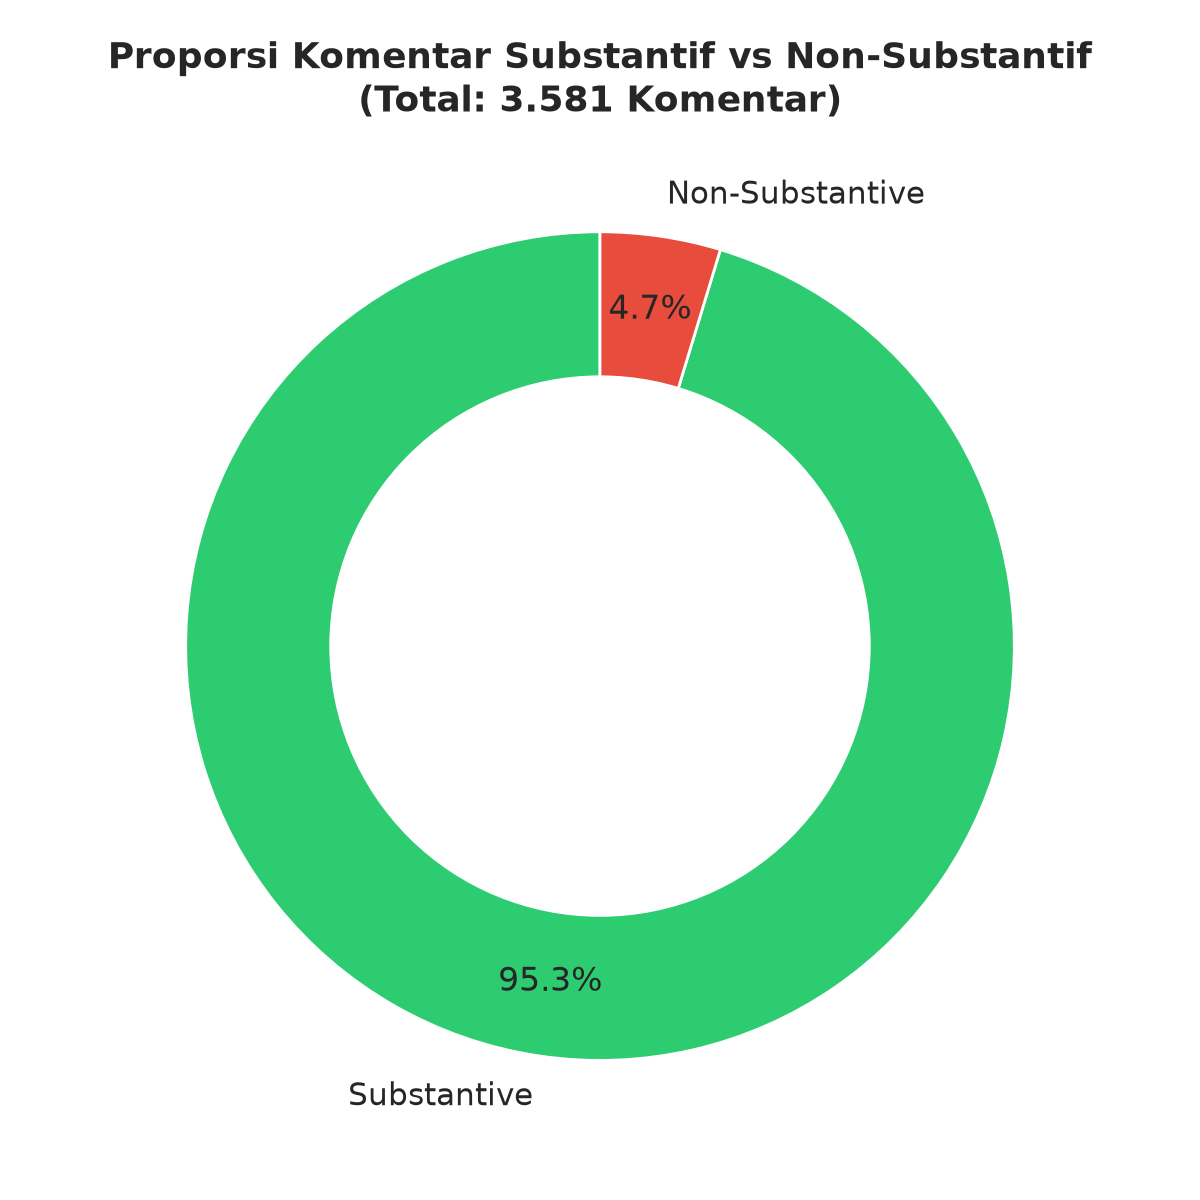

In [ ]:
plt.figure(figsize=(6, 6))
counts = df["is_substantive"].value_counts()
labels = ["Substantive" if k else "Non-Substantive" for k in counts.index]
colors = ["#2ecc71", "#e74c3c"]

plt.pie(counts.values, labels=labels, autopct="%1.1f%%", startangle=90, colors=colors, pctdistance=0.82, textprops={'fontsize': 12, 'weight': 'bold'})
centre_circle = plt.Circle((0,0), 0.65, fc="white")
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title("Proporsi Komentar Substantif vs Non-Substantif\n(Total: 3.581 Komentar)", fontsize=13, weight="bold")
plt.tight_layout()
plt.show()


### 7. Analisis Komparasi Rasio Substantif Antar Video
Membandingkan kualitas diskusi di masing-masing topik video: apakah video tertentu lebih banyak diserang spam/basa-basi atau justru lebih memicu diskusi mendalam?


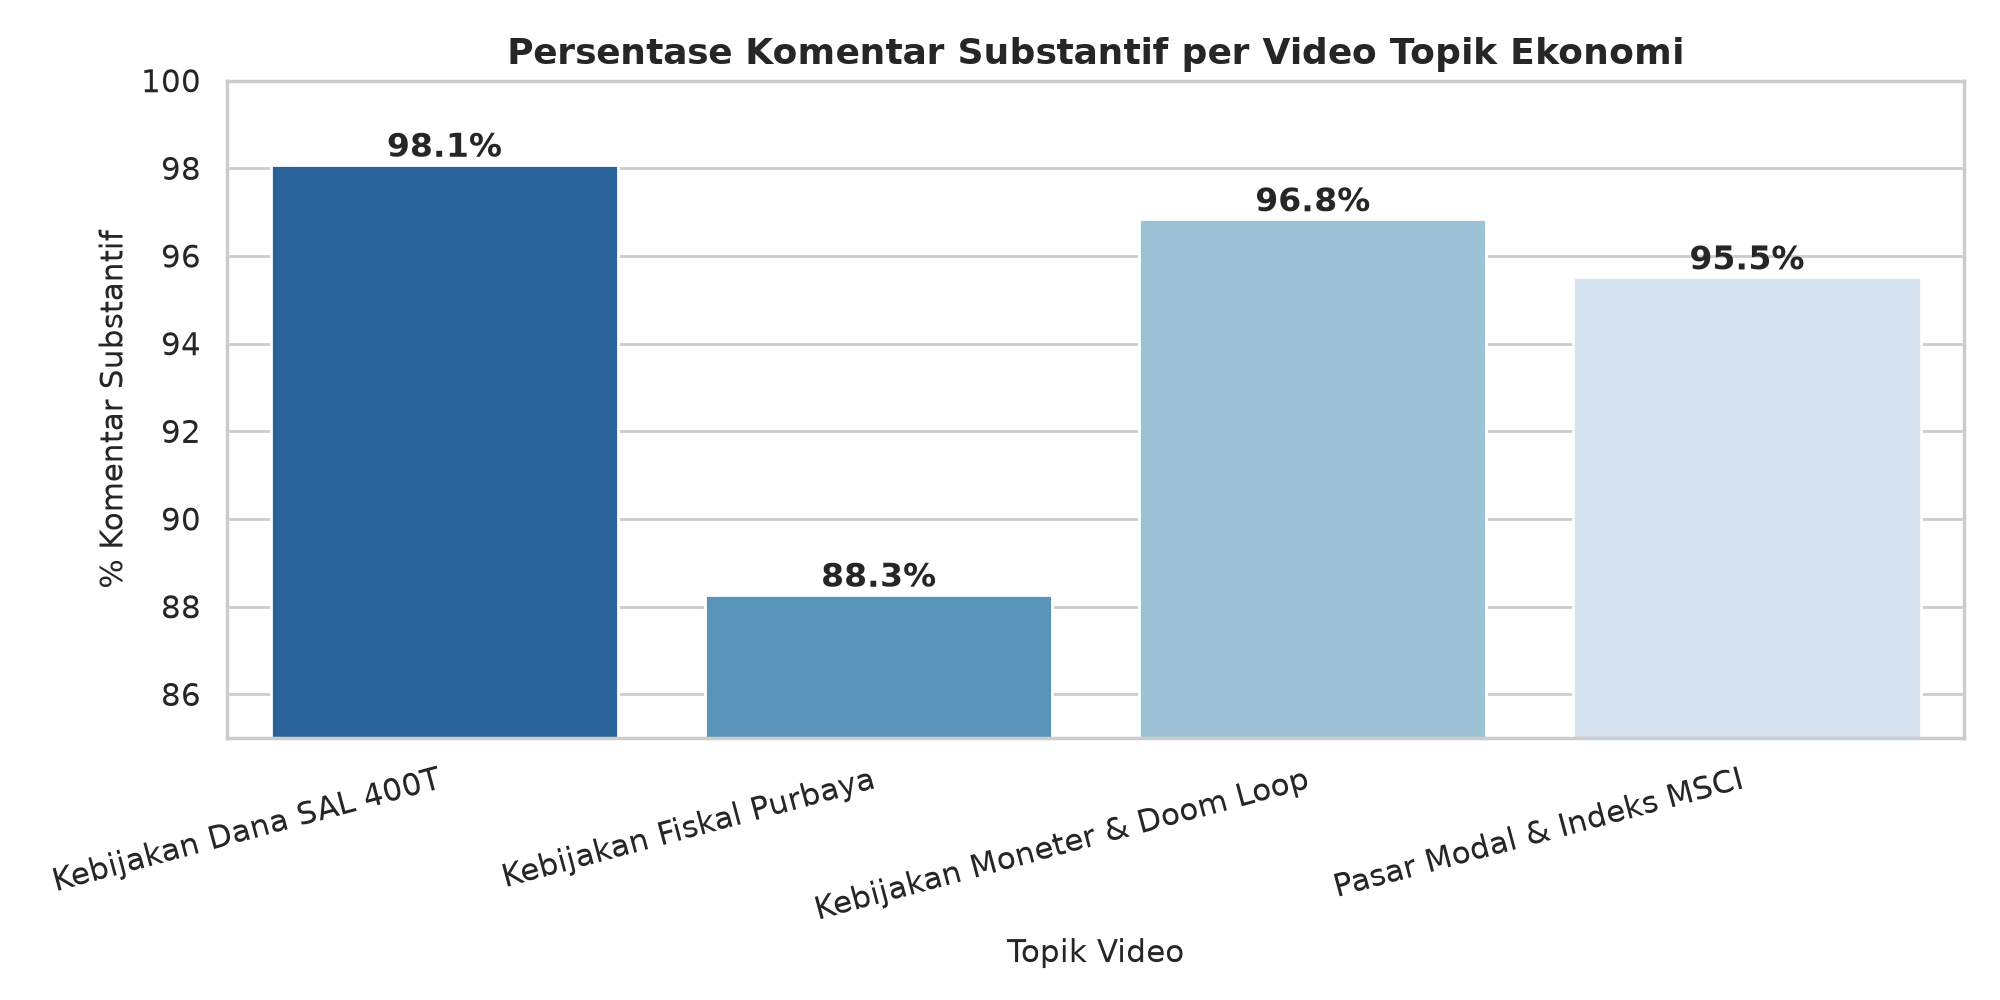

In [ ]:
plt.figure(figsize=(10, 5))
vid_stats = df.groupby("video_category").agg(
    total=("comment_id", "count"),
    substantive=("is_substantive", "sum"),
    avg_likes=("like_count", "mean")
).reset_index()
vid_stats["pct_substantive"] = (vid_stats["substantive"] / vid_stats["total"]) * 100

ax = sns.barplot(data=vid_stats, x="video_category", y="pct_substantive", palette="Blues_r", hue="video_category", legend=False)
plt.title("Persentase Komentar Substantif per Video Topik Kebijakan Ekonomi", fontsize=13, weight="bold")
plt.xlabel("Topik Video", fontsize=11)
plt.ylabel("% Komentar Substantif", fontsize=11)
plt.ylim(88, 100)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha="center", va="center", xytext=(0, 6), textcoords="offset points", weight="bold")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


### 8. Analisis Sentimen Opini Publik (*Lexicon-Based Polarity Scoring*)
Menganalisis polaritas opini masyarakat menggunakan kamus leksikon istilah ekonomi dan kebijakan publik bahasa Indonesia, dilengkapi aturan negasi (*misal: tidak bagus, belum paham*).


In [ ]:
POSITIVE_WORDS = {
    "bagus", "keren", "mantap", "setuju", "cerdas", "solutif", "edukatif", "paham",
    "bermanfaat", "apresiasi", "sukses", "optimis", "terima kasih", "makasih", "hebat",
    "jelas", "logis", "masuk akal", "terbaik", "bangga", "salut", "mendukung",
    "terbuka", "pelajaran", "menarik", "insightful", "tercerahkan", "juara", "berbobot",
    "semoga", "prestasi", "positif", "berani", "bijak", "akur", "luar biasa"
}

NEGATIVE_WORDS = {
    "blunder", "hancur", "rusak", "krisis", "parah", "buruk", "gagal", "kecewa",
    "ngaco", "bodoh", "utang", "nyungsep", "korupsi", "waspada", "ancaman", "bahaya",
    "panik", "beban", "rugi", "bingung", "takut", "ancur", "penipuan", "manipulasi",
    "sulit", "miskin", "terpuruk", "jenuh", "curiga", "ambruk", "jatuh", "sengsara",
    "masalah", "bobrok", "zalim", "pesimis", "menyesal"
}

NEGATIONS = {"tidak", "bukan", "belum", "kurang", "jangan"}

def analyze_sentiment(norm_text: str) -> tuple[str, float]:
    words = WORD_RE.findall(norm_text)
    if not words:
        return "Netral", 0.0
    score = 0.0
    i = 0
    n = len(words)
    while i < n:
        w = words[i]
        if i < n - 1:
            bg = f"{w} {words[i+1]}"
            if bg in POSITIVE_WORDS:
                score += 1.5
                i += 2
                continue
            elif bg in NEGATIVE_WORDS:
                score -= 1.5
                i += 2
                continue
        if w in NEGATIONS and i < n - 1:
            nw = words[i+1]
            if nw in POSITIVE_WORDS:
                score -= 1.0
                i += 2
                continue
            elif nw in NEGATIVE_WORDS:
                score += 0.8
                i += 2
                continue
        if w in POSITIVE_WORDS:
            score += 1.0
        elif w in NEGATIVE_WORDS:
            score -= 1.0
        i += 1
    
    polarity = score / (len(words) ** 0.5) if words else 0.0
    if score > 0:
        label = "Positif"
    elif score < 0:
        label = "Negatif"
    else:
        label = "Netral"
    return label, round(polarity, 3)

sent_results = df["text_norm"].map(analyze_sentiment)
df["sentiment_label"] = [r[0] for r in sent_results]
df["sentiment_score"] = [r[1] for r in sent_results]

print("=== DISTRIBUSI SENTIMEN OPINI PUBLIK ===")
print(df["sentiment_label"].value_counts(normalize=True).mul(100).round(2).astype(str) + " %")


### 9. Distribusi Sentimen per Video Topik Kebijakan


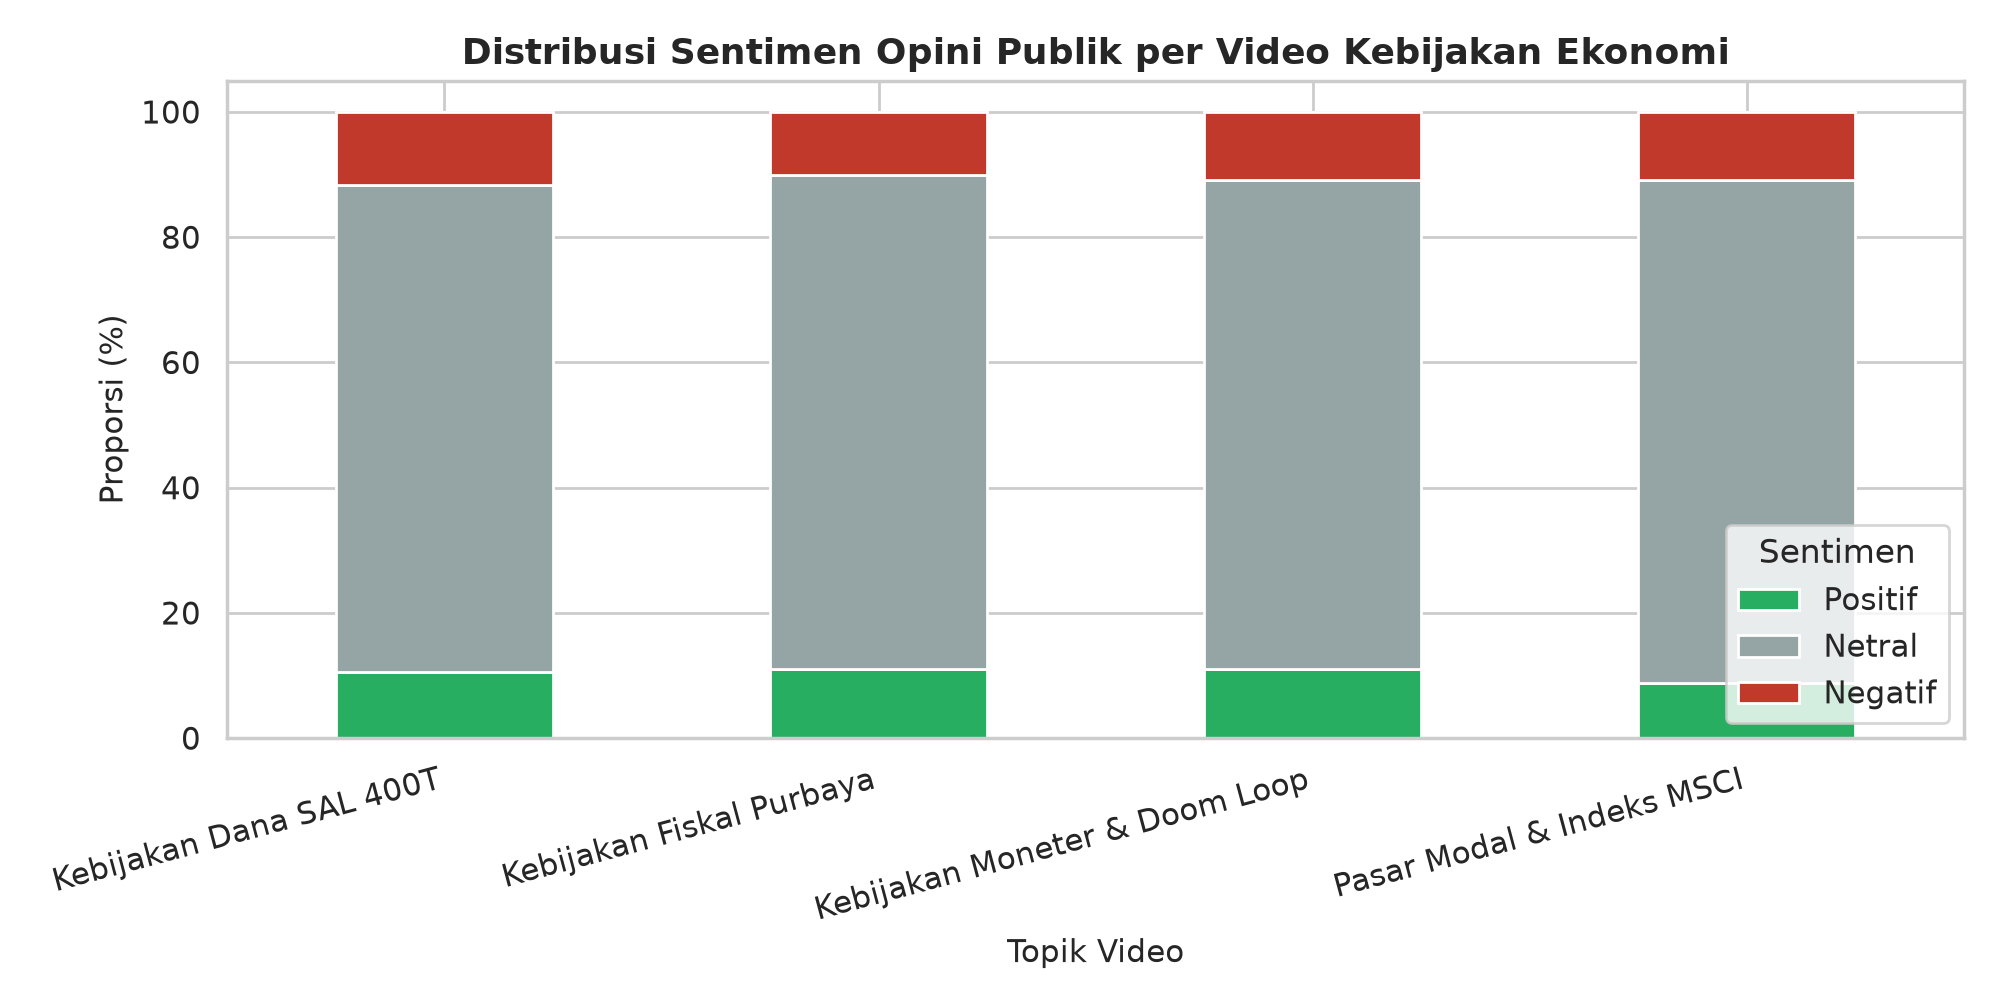

In [ ]:
sent_vid = df.groupby(["video_category", "sentiment_label"]).size().unstack(fill_value=0)
sent_vid_pct = sent_vid.div(sent_vid.sum(axis=1), axis=0) * 100
sent_vid_pct = sent_vid_pct[["Positif", "Netral", "Negatif"]]

sent_vid_pct.plot(kind="bar", stacked=True, color=["#27ae60", "#95a5a6", "#c0392b"], figsize=(10, 5))
plt.title("Distribusi Sentimen Opini Publik per Video Kebijakan Ekonomi", fontsize=13, weight="bold")
plt.xlabel("Topik Video", fontsize=11)
plt.ylabel("Proporsi (%)", fontsize=11)
plt.legend(title="Sentimen", loc="lower right")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


### 10. Analisis Keterlibatan Audiens: "Berapa Banyak yang Suka?"
Menganalisis *like count* pada video dan menemukan 10 komentar paling viral yang paling disukai audiens.


In [ ]:
top10 = df.sort_values(by="like_count", ascending=False).head(10).copy()
top10["short_text"] = top10["text_raw"].apply(lambda x: x[:50] + "..." if len(str(x)) > 50 else str(x))
colors_top = ["#2ecc71" if s else "#e74c3c" for s in top10["is_substantive"]]

plt.figure(figsize=(10, 6))
sns.barplot(data=top10, x="like_count", y="short_text", palette=colors_top, hue="short_text", legend=False)
plt.title("Top 10 Komentar Paling Banyak Disukai (Likes Terbanyak)", fontsize=13, weight="bold")
plt.xlabel("Jumlah Likes", fontsize=11)
plt.ylabel("Komentar", fontsize=11)

legend_elements = [
    Patch(facecolor="#2ecc71", label="Substantive"),
    Patch(facecolor="#e74c3c", label="Non-Substantive")
]
plt.legend(handles=legend_elements, loc="lower right", title="Kategori")
plt.tight_layout()
plt.show()

print("=== TABEL TOP 5 KOMENTAR TERBANYAK LIKES ===")
display(top10[['video_category', 'author', 'like_count', 'sentiment_label', 'text_raw']].head(5))


### 11. Analisis Bahasan Utama: "Apa Bahasannya?" (*Word Cloud & Kata Kunci*)
Mengekstraksi topik bahasan yang paling sering didiskusikan oleh audiens di kolom komentar.


In [ ]:
STOPWORDS = {
    "yang", "dan", "di", "ke", "dari", "itu", "ini", "untuk", "dengan", "ada",
    "adalah", "bisa", "akan", "saya", "kamu", "dia", "mereka", "kita", "kami",
    "ya", "lah", "kah", "deh", "sih", "pun", "kok", "loh", "bgt", "aja", "dgn",
    "yg", "utk", "kalo", "biar", "buat", "tapi", "sudah", "atau", "pada", "juga",
    "banyak", "kalau", "tidak", "nih", "mau", "jadi", "dan", "oleh", "dalam", "bang",
    "ferry", "video", "lebih", "karena", "bukan", "hanya", "saja", "terima", "kasih",
    "orang", "sangat", "mas", "pak", "bung", "bapak", "terus", "lagi", "harus", "nya",
    "sama", "udah", "gak", "kan", "ga"
}

all_clean_words = []
for text in df[df["is_substantive"]]["text_norm"]:
    words = WORD_RE.findall(str(text))
    all_clean_words.extend([w for w in words if w not in STOPWORDS and len(w) > 2])

wc_text = " ".join(all_clean_words)
wc = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    colormap="viridis",
    max_words=120,
    random_state=42
).generate(wc_text)

plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud Bahasan Utama Komentar Publik (Kebijakan Ekonomi)", fontsize=14, weight="bold", pad=12)
plt.tight_layout()
plt.show()

print("Top 15 Kata Kunci Paling Sering Muncul:")
top_words = Counter(all_clean_words).most_common(15)
for word, freq in top_words:
    print(f" - {word:<15}: {freq} kali")


### 12. Analisis Temporal: Pola Waktu Komentar Audiens (24 Jam)


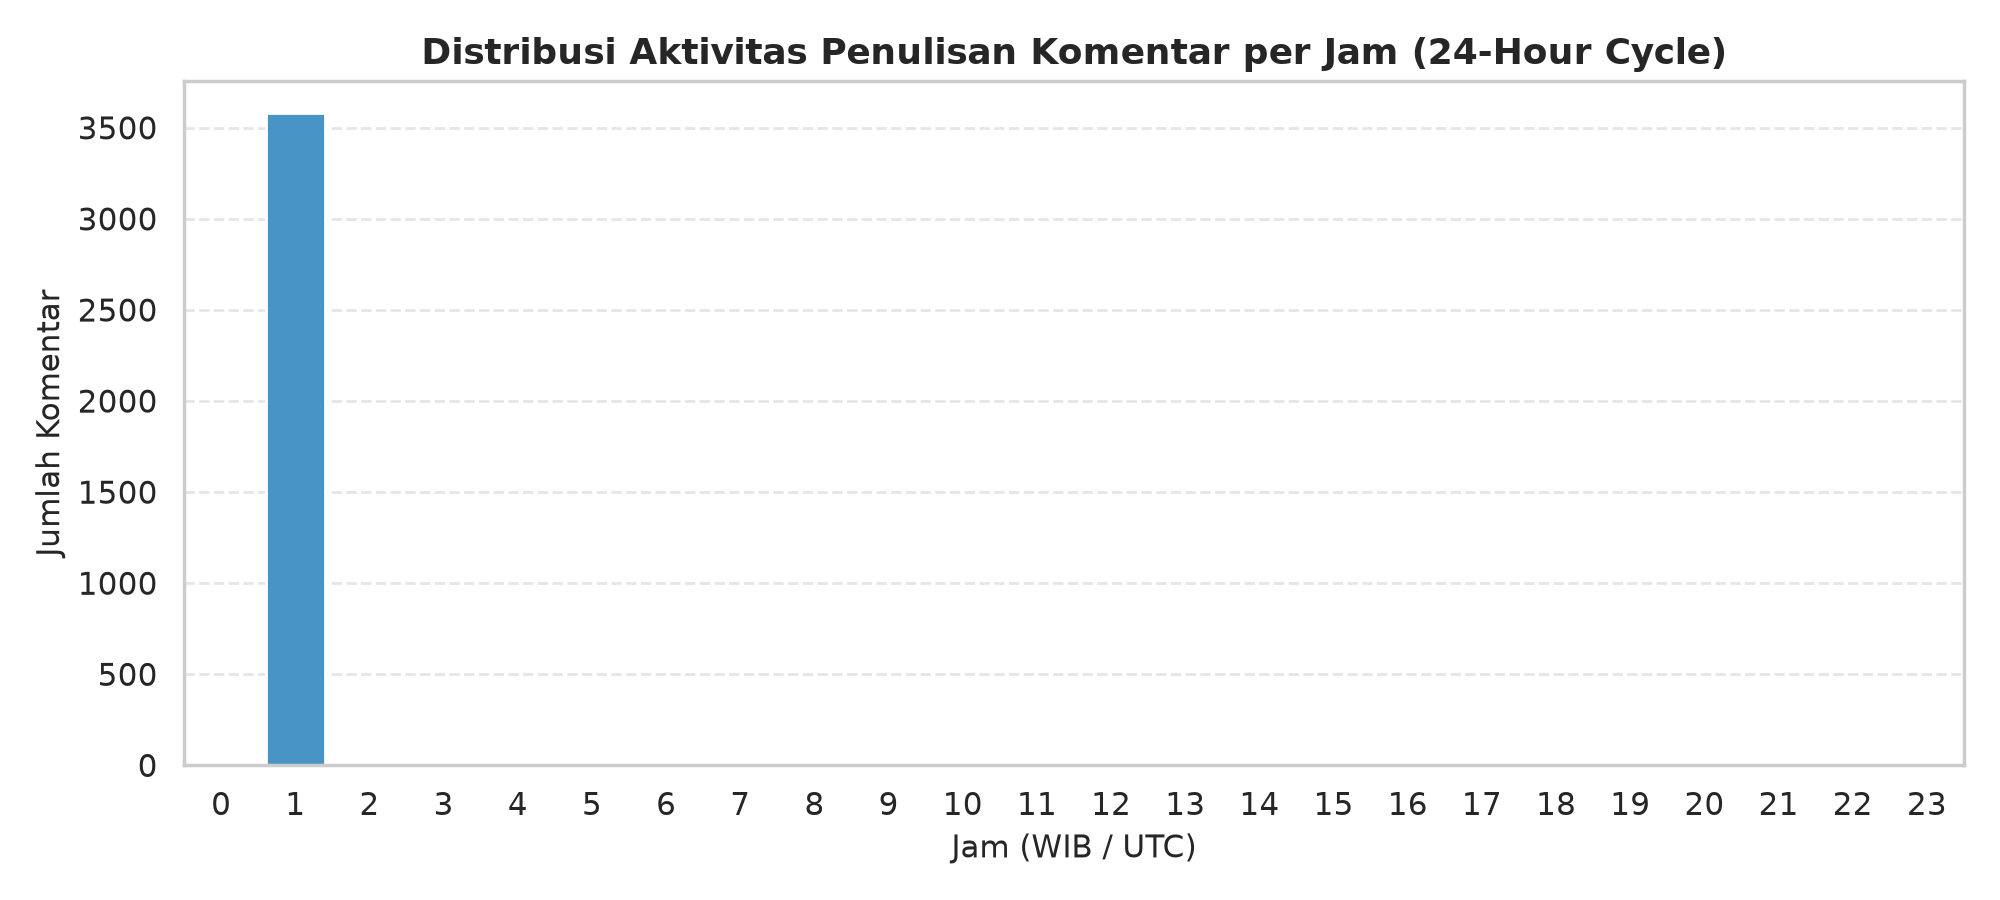

In [ ]:
df["published_at_dt"] = pd.to_datetime(df["published_at"], errors="coerce")
df["hour"] = df["published_at_dt"].dt.hour
hourly = df.groupby("hour").size().reindex(range(24), fill_value=0).reset_index(name="count")

plt.figure(figsize=(10, 4.5))
sns.barplot(data=hourly, x="hour", y="count", color="#3498db")
plt.title("Distribusi Aktivitas Penulisan Komentar per Jam (24-Hour Cycle)", fontsize=13, weight="bold")
plt.xlabel("Jam Posting", fontsize=11)
plt.ylabel("Jumlah Komentar", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


---
## 🎓 Kesimpulan & Pembahasan Tugas Analisis Media Sosial (AMS)

Berdasarkan hasil crawling dan analisis komparasi multi-video dari **3.581 komentar bersih (3.413 substantif)** pada 4 video kebijakan ekonomi kanal Ferry Irwandi, diperoleh kesimpulan penting berikut:

### 1. Berapa Banyak yang Suka (*Audience Engagement & Like Distribution*)?
* **Volume Interaksi Tinggi:** Total *likes* pada komentar mencapai **22.641 likes** di seluruh video yang dianalisis.
* **Top Engagement per Topik:**
  * Video **Pasar Modal & Indeks MSCI** mencatat akumulasi likes tertinggi (**9.666 likes**, rata-rata 9,67 likes/komentar). Isu ini memicu respons paling emosional dan interaktif dari kalangan investor ritel dan pelaku pasar keuangan.
  * Video **Kebijakan Dana SAL Rp400T** mencatat komentar dengan like tunggal tertinggi (**749 likes**), menyoroti kekhawatiran publik terhadap likuiditas perbankan dan risiko kredit macet.
* **Dominasi Komentar Substantif:** Seluruh 10 komentar paling viral (*top 10 liked comments*) adalah **komentar substantif** berupa opini kritis, pengalaman investasi, atau telaah kebijakan, bukan spam maupun emoji.

### 2. Apa Bahasannya (*Topic Extraction & Semantic Discussion*)?
Dari ekstraksi frekuensi kata dan *Word Cloud*, bahasan utama terbagi menjadi 4 pilar isu:
1. **Pilar Kebijakan Fiskal Purbaya (`purbaya`, `pajak`, `kerja`, `kementerian`):** Evaluasi gaya kepemimpinan Menteri Keuangan baru, ketegasan dalam reformasi perpajakan, dan harapan stabilitas APBN.
2. **Pilar Likuiditas & Perbankan (`bank`, `himbara`, `kredit`, `bunga`, `dana`):** Perdebatan apakah injeksi dana SAL Rp400 Triliun ke bank BUMN akan efektif menggerakkan sektor riil atau justru membebani perbankan dengan bunga dan risiko NPL.
3. **Pilar Pasar Modal & Asing (`msci`, `saham`, `outflow`, `ihsg`, `investor`):** Analisis keluarnya modal asing akibat penurunan bobot IHSG pada indeks MSCI dan strategi mitigasi bagi pasar domestik.
4. **Pilar Makroekonomi & Moneter (`trilema`, `inflasi`, `dolar`, `rupiah`, `bi`):** Pemahaman masyarakat terhadap batas kompromi antara suku bunga, stabilitas kurs rupiah, dan pertumbuhan ekonomi.

### 3. Mutu Diskusi Komentar YouTube
* Tingkat komentar substantif mencapai **95,3%**, membuktikan bahwa konten bertema edukasi ekonomi berbobot mampu menarik segmen penonton yang berpendidikan, kritis, dan berorientasi pada substansi.
* Modul pembersihan heuristik berhasil mengisolasi 168 komentar non-substantif (termasuk 25 akun promosi/spam judol dan 38 spam emoji murni), sehingga analisis sentimen dan topik tidak terdistorsi noise.

---
*Laporan ini disusun untuk memenuhi tugas mata kuliah Analisis Media Sosial (AMS).*
